# Lecture 1 companion — which production capacity is worth buying?
**Instructor demonstration: 15–20 minutes.** This notebook follows the lecture's Wyndor data, with a capacity-purchase decision and independently checked results. The data are a textbook teaching scenario, not current industrial measurements.

**Prerequisites:** Python functions, linear equations, inequalities. Run cells from the top. Install once in your environment if needed: `python -m pip install numpy scipy matplotlib pandas ipywidgets jupyterlab`. Widgets are optional: every experiment is an ordinary callable function. No network or solver service is needed after installation.

**Route:** predict a plan → solve and inspect resources → change assumptions → evaluate a capacity offer. The companion is a short lecture demonstration. [Lab 1](https://github.com/AdoHaha/automation_robotics_lab/blob/master/lab_auto_1.ipynb) uses different robot-kit data and teaches building PuLP models. [Lab 3](https://github.com/AdoHaha/automation_robotics_lab/blob/master/lab_auto_3.ipynb) develops transportation and flow models. Lab alignment checked against commit `3c1b7a70f5990d7665b11a7a853eaf1061a36d30`.

## 1. Predict before solving
Let $x_1,x_2$ be batches per week. Contribution is $3x_1+5x_2$ **thousand dollars/week**. All output can be sold, coefficients are constant, and batches may be fractional.

| Resource | Hours / batch P1 | Hours / batch P2 | Hours / week |
|---|---:|---:|---:|
| Plant 1 | 1 | 0 | 4 |
| Plant 2 | 0 | 2 | 12 |
| Plant 3 | 3 | 2 | 18 |

**Prediction:** is `(4, 6)` feasible? Is making only the higher-profit P2 best? Which plant would you expand first? Record a reason before running the solution.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import linprog, milp, Bounds, LinearConstraint
from IPython.display import display
# All teaching data below are explicit and deterministic. No files or downloads.
np.set_printoptions(precision=4, suppress=True)


In [2]:
A = np.array([[1., 0.], [0., 2.], [3., 2.]])
BASE_CAPACITY = np.array([4., 12., 18.])
PROFIT = np.array([3., 5.])

def solve_mix(plant3_hours=18., p2_profit=5., plant1_hours=4., minimum=(0., 0.)):
    """Hours/week and k$/batch in; scipy result and physical input data out."""
    b = np.array([plant1_hours, 12., plant3_hours], dtype=float)
    c = np.array([3., p2_profit])
    result = linprog(-c, A_ub=A, b_ub=b,
                     bounds=[(float(m), None) for m in minimum], method='highs')
    return result, b, c

base, b, c = solve_mix()
assert base.success, base.message
assert np.allclose(base.x, [2, 6]) and np.isclose(-base.fun, 36)
assert np.all(A @ base.x <= b + 1e-8)
print('Optimal batches/week:', base.x, '| profit k$/week:', -base.fun)
display(pd.DataFrame({'used hours': A @ base.x, 'available hours': b,
                      'slack hours': b - A @ base.x}, index=['Plant 1', 'Plant 2', 'Plant 3']))


Optimal batches/week: [2. 6.] | profit k$/week: 36.0


,used hours,available hours,slack hours
Plant 1,2.0,4.0,2.0
Plant 2,12.0,12.0,0.0
Plant 3,18.0,18.0,0.0


**Interpretation:** `(4,6)` needs 24 Plant 3 hours, exceeding 18. `(0,6)` yields 30 k$/week. Adding two batches of P1 uses the six remaining Plant 3 hours and raises contribution to 36. Plant 1 still has two idle hours.

A binding row has zero slack. A shadow price measures the **local change in optimal contribution per added hour**. These describe different properties. A binding constraint can have zero shadow price in degenerate cases.

Plan [2. 6.] batches/week; contribution 36.000 k$/week


,used h/week,slack h/week
Plant 1,2.0,2.0
Plant 2,12.0,0.0
Plant 3,18.0,0.0


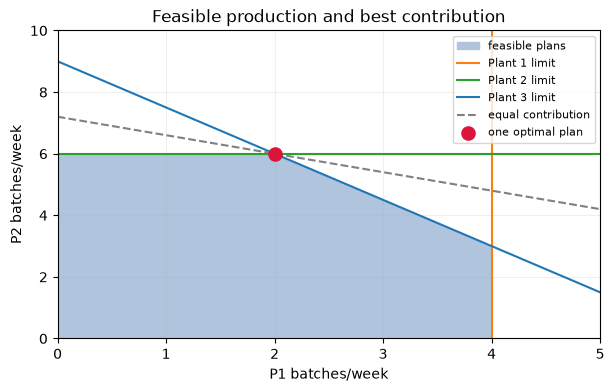

In [3]:
def mix_experiment(plant3_hours=18., p2_profit=5., plant1_hours=4., min_p1=0.):
    result, b, c = solve_mix(plant3_hours, p2_profit, plant1_hours, (min_p1, 0.))
    if not result.success:
        print('No usable production plan:', result.message)
        return result
    print(f'Plan {result.x.round(3)} batches/week; contribution {-result.fun:.3f} k$/week')
    display(pd.DataFrame({'used h/week': A @ result.x, 'slack h/week': b-A @ result.x},
                         index=['Plant 1', 'Plant 2', 'Plant 3']))
    grid = np.linspace(0, max(5., plant1_hours + 1), 500)
    top = np.minimum(6., (plant3_hours - 3*grid)/2)
    valid = (grid >= min_p1) & (grid <= plant1_hours) & (top >= 0)
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.fill_between(grid, 0, np.maximum(0, top), where=valid, color='lightsteelblue',
                    label='feasible plans')
    ax.axvline(plant1_hours, color='tab:orange', label='Plant 1 limit')
    ax.axhline(6, color='tab:green', label='Plant 2 limit')
    ax.plot(grid, (plant3_hours - 3*grid)/2, color='tab:blue', label='Plant 3 limit')
    ax.plot(grid, (-result.fun - c[0]*grid)/c[1], '--', color='gray', label='equal contribution')
    ax.scatter(*result.x, s=90, color='crimson', zorder=5, label='one optimal plan')
    ax.set(xlim=(0, grid[-1]), ylim=(0, max(8, plant3_hours/2+1)),
           xlabel='P1 batches/week', ylabel='P2 batches/week', title='Feasible production and best contribution')
    ax.legend(loc='upper right', fontsize=8); ax.grid(alpha=.2); plt.show()
    return result

# Fallback call: edit the arguments and run again if widgets are unavailable.
_ = mix_experiment()


## 2. A controlled experiment
**Predict:** add two hours to Plant 1 only. Then add two to Plant 3 only. Does the higher-profit product always dominate if P2 profit falls to 2? At `p2_profit=2`, several plans may have equal contribution; a solver returns one.

Change one input at a time. Record the plan, contribution, and which resource now limits production.

In [4]:
try:
    import ipywidgets as widgets
except ImportError:
    print('Widgets unavailable. Use mix_experiment(plant3_hours=20, p2_profit=5).')
else:
    controls = widgets.interactive(
        mix_experiment,
        plant3_hours=widgets.FloatSlider(value=18, min=8, max=30, step=1,
                                        description='Plant 3 h', continuous_update=False),
        p2_profit=widgets.FloatSlider(value=5, min=1, max=8, step=.5,
                                     description='P2 k$/batch', continuous_update=False),
        plant1_hours=widgets.FloatSlider(value=4, min=1, max=8, step=.5,
                                         description='Plant 1 h', continuous_update=False),
        min_p1=widgets.FloatSlider(value=0, min=0, max=5, step=.5,
                                  description='Min P1', continuous_update=False))
    display(controls)


interactive(children=(FloatSlider(value=18.0, continuous_update=False, description='Plant 3 h', max=30.0, min=…

## 3. Local value and a finite capacity purchase
SciPy minimizes $-Z$, so `ineqlin.marginals` reports derivatives of **negative contribution** with respect to right-hand sides. Negate them for the maximization interpretation.

**Predict:** should we buy 5 extra Plant 3 hours for 4 k$/week? What about 12 extra hours for 10 k$/week? Explain why multiplying a local shadow price by 12 could be misleading.

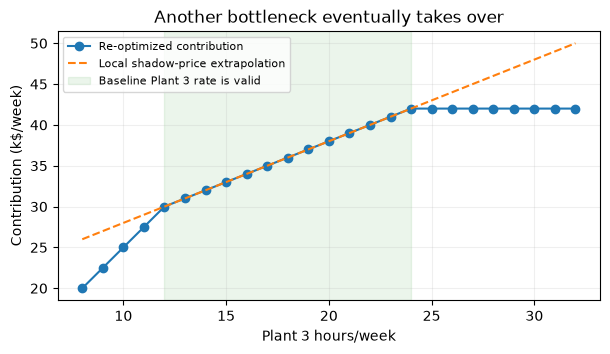

Buy 5 hours for 4 k$/week: gain 5.0, net 1.0 k$/week
Buy 12 hours for 10 k$/week: gain 6.0, net -4.0 k$/week


In [5]:
shadow = -base.ineqlin.marginals
one_more, _, _ = solve_mix(19)
assert np.allclose(shadow, [0, 1.5, 1])
assert np.isclose((-one_more.fun) - (-base.fun), shadow[2])
assert np.isclose(-solve_mix(plant1_hours=5)[0].fun, 36)
capacities = np.arange(8, 33)
values = np.array([-solve_mix(float(h))[0].fun for h in capacities])
assert np.all(np.diff(values) >= -1e-8)
assert np.isclose(values[capacities == 24][0], 42)
assert np.allclose(values[capacities >= 24], 42)
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(capacities, values, 'o-', label='Re-optimized contribution')
ax.plot(capacities, 36 + shadow[2]*(capacities-18), '--', label='Local shadow-price extrapolation')
ax.axvspan(12, 24, color='green', alpha=.08, label='Baseline Plant 3 rate is valid')
ax.set(xlabel='Plant 3 hours/week', ylabel='Contribution (k$/week)', title='Another bottleneck eventually takes over')
ax.legend(fontsize=8); ax.grid(alpha=.2); plt.show()
for extra, price in [(5, 4), (12, 10)]:
    offered, _, _ = solve_mix(18 + extra)
    gain = -offered.fun + base.fun
    print(f'Buy {extra} hours for {price} k$/week: gain {gain:.1f}, net {gain-price:.1f} k$/week')
assert np.isclose(-solve_mix(23)[0].fun + base.fun - 4, 1)
assert np.isclose(-solve_mix(30)[0].fun + base.fun - 10, -4)


**Interpretation:** the first offer nets +1 k$/week. The second nets −4 k$/week. Above 24 Plant 3 hours, Plants 1 and 2 cap contribution at 42 k$/week. The Plant 3 shadow price is locally valid, not a rate for unlimited expansion.

## 4. A solver status is part of the answer
Requiring five P1 batches contradicts Plant 1 capacity. Predict the status, then run. Never interpret stale or absent solver values as a plan.

In [6]:
bad, _, _ = solve_mix(minimum=(5., 0.))
assert bad.status == 2  # Infeasible, not an optimum with low profit.
print(bad.message)
# Independent units/checks: minimum P1=5 consumes 5 h > 4 h in Plant 1.
assert (A @ np.array([5., 0.]))[0] > BASE_CAPACITY[0]


The problem is infeasible. (HiGHS Status 8: model_status is Infeasible; primal_status is None)


## Exit ticket
1. What physical facts justify fractional batches in this planning horizon? When would integers be required?
2. Why might setup time or uncertain demand make the calculated optimum unsuitable for tomorrow?
3. In the lecture's transportation table, supply totals 5000 crates and demand 4100. Why do equalities forcing all supply to ship contradict exact demand? Explain either unused-stock inequalities or a 900-crate storage node.

**Sources:** mathematical data and notation follow `lecture_1.tex`. Solver behavior follows the [official SciPy `linprog` reference](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.linprog.html).